#### 1. Analyzing the dataset

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('job_dataset.csv')

In [4]:
df.columns

Index(['Candidate_ID', 'Gender', 'Education', 'Experience_Years', 'Skills',
       'Aptitude_Score', 'Interview_Score', 'Hiring_Status', 'Age', 'City',
       'Graduation_Year', 'Certification', 'Communication_Score',
       'Coding_Score', 'Expected_Salary_LPA', 'Notice_Period_Days',
       'Internship_Experience', 'Applied_Role'],
      dtype='str')

In [5]:
df.shape

(500, 18)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Candidate_ID           500 non-null    str    
 1   Gender                 436 non-null    str    
 2   Education              446 non-null    str    
 3   Experience_Years       457 non-null    str    
 4   Skills                 473 non-null    str    
 5   Aptitude_Score         462 non-null    str    
 6   Interview_Score        465 non-null    str    
 7   Hiring_Status          446 non-null    str    
 8   Age                    488 non-null    float64
 9   City                   485 non-null    str    
 10  Graduation_Year        483 non-null    float64
 11  Certification          386 non-null    str    
 12  Communication_Score    488 non-null    float64
 13  Coding_Score           488 non-null    float64
 14  Expected_Salary_LPA    485 non-null    float64
 15  Notice_Period_Day

In [7]:
for column in ['Gender', 'Education', 'Experience_Years', 'Skills',
               'Aptitude_Score', 'Interview_Score', 'Hiring_Status',
               'Age', 'City', 'Graduation_Year', 'Certification',
               'Communication_Score', 'Coding_Score',
               'Expected_Salary_LPA', 'Notice_Period_Days',
               'Internship_Experience', 'Applied_Role']:

    print(column, df[column].isnull().sum(), sep='-->')

Gender-->64
Education-->54
Experience_Years-->43
Skills-->27
Aptitude_Score-->38
Interview_Score-->35
Hiring_Status-->54
Age-->12
City-->15
Graduation_Year-->17
Certification-->114
Communication_Score-->12
Coding_Score-->12
Expected_Salary_LPA-->15
Notice_Period_Days-->12
Internship_Experience-->15
Applied_Role-->12


#### 2. Cleaning the dataset

In [8]:
df.duplicated().any()

np.False_

In [9]:
#this column has  str value so,we can't get mean value for this.
print(df['Experience_Years'].dtype)
print(df['Experience_Years'].unique())

str
<StringArray>
[ '10',   '0',   nan,   '6',   '4',   '1',   '9',   '3',   '8',  '-1',   '7',
   '2',  '11',   '5',  '25', 'two',  '12']
Length: 17, dtype: str


In [10]:
df['Experience_Years'] = pd.to_numeric(
    df['Experience_Years'], errors='coerce' #it change the invalid value into NaN
)
df['Experience_Years']

0      10.0
1       0.0
2       NaN
3       6.0
4       4.0
       ... 
495    25.0
496     7.0
497     4.0
498     5.0
499    11.0
Name: Experience_Years, Length: 500, dtype: float64

In [11]:
Exp_mean = df['Experience_Years'].mean()
Exp_mean

np.float64(6.635746606334842)

In [12]:
df['Experience_Years']=df['Experience_Years'].fillna(Exp_mean)

In [13]:
df.head()

,Candidate_ID,Gender,Education,Experience_Years,Skills,Aptitude_Score,Interview_Score,Hiring_Status,Age,City,Graduation_Year,Certification,Communication_Score,Coding_Score,Expected_Salary_LPA,Notice_Period_Days,Internship_Experience,Applied_Role
0,C1001,Female,NaN,10.000000,"Excel, SQL",55,3,Selected,21.0,Chennai,2025.0,Django,9.0,70.0,8.7,7.0,No,NaN
1,C1002,NaN,BCA,0.000000,"HTML, CSS, JavaScript",84,9,Reject,28.0,Mumbai,2024.0,AWS,1.0,10.0,11.6,90.0,No,Python Developer
2,C1003,male,M.Tech,6.635747,Java,40,6,Rejected,27.0,Mysuru,2023.0,AWS,4.0,76.0,5.7,0.0,No,Software Tester
3,C1004,Female,MBA,6.000000,Java,64,1,Hire,25.0,Delhi,2025.0,Power BI,5.0,11.0,6.3,15.0,No,Software Tester
4,C1005,male,MCA,4.000000,Java,66,2,selected,25.0,Hyderabad,2019.0,NaN,8.0,6.0,10.1,60.0,Yes,Data Analyst


In [14]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [15]:
df['Gender']

0      Female
1       Other
2        male
3      Female
4        male
        ...  
495    Female
496      Male
497      male
498      Male
499    female
Name: Gender, Length: 500, dtype: str

In [16]:
df['Education'] = df['Education'].fillna(df['Education'].mode()[0])

In [17]:
df['Education']

0      Diploma
1          BCA
2       M.Tech
3          MBA
4          MCA
        ...   
495       b.e.
496       b.e.
497     B.Tech
498       B.E.
499    Diploma
Name: Education, Length: 500, dtype: str

In [18]:
df['Skills'] = df['Skills'].fillna(df['Skills'].mode()[0])

In [19]:
df['Skills']

0                 Excel, SQL
1      HTML, CSS, JavaScript
2                       Java
3                       Java
4                       Java
               ...          
495           Python, Pandas
496            Data Analysis
497              Python, SQL
498         Machine Learning
499                   Python
Name: Skills, Length: 500, dtype: str

In [20]:
df['Hiring_Status'] = df['Hiring_Status'].fillna(df['Hiring_Status'].mode()[0])

In [21]:
df['Hiring_Status']

0      Selected
1        Reject
2      Rejected
3          Hire
4      selected
         ...   
495    selected
496    Rejected
497     Pending
498    SELECTED
499    Selected
Name: Hiring_Status, Length: 500, dtype: str

In [22]:
df['City'] = df['City'].fillna(df['City'].mode()[0])
df['City']

0         Chennai
1          Mumbai
2          Mysuru
3           Delhi
4       Hyderabad
          ...    
495        Mumbai
496    Coimbatore
497          Pune
498        Mysuru
499    Coimbatore
Name: City, Length: 500, dtype: str

In [23]:
df['Certification'] = df['Certification'].fillna('Not Specified')
df['Certification']

0             Django
1                AWS
2                AWS
3           Power BI
4      Not Specified
           ...      
495           Python
496    Not Specified
497    Not Specified
498              AWS
499              AWS
Name: Certification, Length: 500, dtype: str

In [24]:
df['Internship_Experience'] = df['Internship_Experience'].fillna(df['Internship_Experience'].mode()[0])
df['Internship_Experience']

0       No
1       No
2       No
3       No
4      Yes
      ... 
495    Yes
496     No
497     No
498     No
499    Yes
Name: Internship_Experience, Length: 500, dtype: str

In [25]:
df['Applied_Role'] = df['Applied_Role'].fillna(df['Applied_Role'].mode()[0])
df['Applied_Role']

0             Web Developer
1          Python Developer
2           Software Tester
3           Software Tester
4              Data Analyst
               ...         
495            Data Analyst
496       Backend Developer
497           Web Developer
498    Full Stack Developer
499        Python Developer
Name: Applied_Role, Length: 500, dtype: str

In [26]:
df['Aptitude_Score'] = pd.to_numeric(
    df['Aptitude_Score'], errors='coerce'
)

df['Interview_Score'] = pd.to_numeric(
    df['Interview_Score'], errors='coerce'
)

In [27]:
num_cols = [
    'Aptitude_Score',
    'Interview_Score',
    'Age',
    'Graduation_Year',
    'Communication_Score',
    'Coding_Score',
    'Expected_Salary_LPA',
    'Notice_Period_Days'
]


for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())


In [28]:
print(df[num_cols].dtypes)

Aptitude_Score         float64
Interview_Score        float64
Age                    float64
Graduation_Year        float64
Communication_Score    float64
Coding_Score           float64
Expected_Salary_LPA    float64
Notice_Period_Days     float64
dtype: object


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Candidate_ID           500 non-null    str    
 1   Gender                 500 non-null    str    
 2   Education              500 non-null    str    
 3   Experience_Years       500 non-null    float64
 4   Skills                 500 non-null    str    
 5   Aptitude_Score         500 non-null    float64
 6   Interview_Score        500 non-null    float64
 7   Hiring_Status          500 non-null    str    
 8   Age                    500 non-null    float64
 9   City                   500 non-null    str    
 10  Graduation_Year        500 non-null    float64
 11  Certification          500 non-null    str    
 12  Communication_Score    500 non-null    float64
 13  Coding_Score           500 non-null    float64
 14  Expected_Salary_LPA    500 non-null    float64
 15  Notice_Period_Day

In [30]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [31]:
text_cols = df.select_dtypes(include='object').columns

for col in text_cols:
    df[col] = df[col].str.strip()

C:\Users\Kousalya\AppData\Local\Temp\ipykernel_23180\2669581636.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include='object').columns


In [32]:
score_cols = [
    'Aptitude_Score',
    'Interview_Score',
    'Communication_Score',
    'Coding_Score'
]

df['Average_Score'] = df[score_cols].mean(axis=1)

In [33]:
df['Experience_Level'] = pd.cut(
    df['Experience_Years'],
    bins=[-1, 0, 2, 5, float('inf')],
    labels=['Fresher', 'Beginner', 'Intermediate', 'Experienced']
)

In [34]:
df['Skill_Count'] = df['Skills'].apply(
    lambda x: len(x.split(',')) if pd.notna(x)
    and x != 'Not Provided' else 0
)

In [35]:
df['Salary_Band'] = pd.cut(
    df['Expected_Salary_LPA'],
    bins=[-float('inf'), 3, 6, 10, float('inf')],
    labels=['Below 3 LPA', '3–6 LPA', '6–10 LPA', 'Above 10 LPA']
)

In [36]:
df.head()

,Candidate_ID,Gender,Education,Experience_Years,Skills,Aptitude_Score,Interview_Score,Hiring_Status,Age,City,...,Communication_Score,Coding_Score,Expected_Salary_LPA,Notice_Period_Days,Internship_Experience,Applied_Role,Average_Score,Experience_Level,Skill_Count,Salary_Band
0,C1001,Female,Diploma,10.000000,"Excel, SQL",55.0,3.0,Selected,21.0,Chennai,...,9.0,70.0,8.7,7.0,No,Web Developer,34.25,Experienced,2,6–10 LPA
1,C1002,Other,BCA,0.000000,"HTML, CSS, JavaScript",84.0,9.0,Reject,28.0,Mumbai,...,1.0,10.0,11.6,90.0,No,Python Developer,26.00,Fresher,3,Above 10 LPA
2,C1003,male,M.Tech,6.635747,Java,40.0,6.0,Rejected,27.0,Mysuru,...,4.0,76.0,5.7,0.0,No,Software Tester,31.50,Experienced,1,3–6 LPA
3,C1004,Female,MBA,6.000000,Java,64.0,1.0,Hire,25.0,Delhi,...,5.0,11.0,6.3,15.0,No,Software Tester,20.25,Experienced,1,6–10 LPA
4,C1005,male,MCA,4.000000,Java,66.0,2.0,selected,25.0,Hyderabad,...,8.0,6.0,10.1,60.0,Yes,Data Analyst,20.50,Intermediate,1,Above 10 LPA


In [37]:
df.shape

(500, 22)

In [38]:
# Clean the Skills column
df['Skills'] = df['Skills'].fillna('').str.lower().str.strip()

# Create separate columns for each skill
skills = df['Skills'].str.get_dummies(sep=',')

# Remove extra spaces from skill column names
skills.columns = skills.columns.str.strip()

# Add skill columns to the original dataset
df = pd.concat([df, skills], axis=1)

df.head()

,Candidate_ID,Gender,Education,Experience_Years,Skills,Aptitude_Score,Interview_Score,Hiring_Status,Age,City,...,javascript,pandas,sql,data analysis,excel,html,java,machine learning,python,sql
0,C1001,Female,Diploma,10.000000,"excel, sql",55.0,3.0,Selected,21.0,Chennai,...,0,0,1,0,1,0,0,0,0,0
1,C1002,Other,BCA,0.000000,"html, css, javascript",84.0,9.0,Reject,28.0,Mumbai,...,1,0,0,0,0,1,0,0,0,0
2,C1003,male,M.Tech,6.635747,java,40.0,6.0,Rejected,27.0,Mysuru,...,0,0,0,0,0,0,1,0,0,0
3,C1004,Female,MBA,6.000000,java,64.0,1.0,Hire,25.0,Delhi,...,0,0,0,0,0,0,1,0,0,0
4,C1005,male,MCA,4.000000,java,66.0,2.0,selected,25.0,Hyderabad,...,0,0,0,0,0,0,1,0,0,0


In [39]:
df = df.rename(columns={
    'python': 'Python',
    'sql': 'SQL',
    'django': 'Django',
    'java': 'Java',
    'excel': 'Excel'
})

In [40]:
df = df.drop(columns=['Skills'])

In [41]:
df

,Candidate_ID,Gender,Education,Experience_Years,Aptitude_Score,Interview_Score,Hiring_Status,Age,City,Graduation_Year,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,SQL
0,C1001,Female,Diploma,10.000000,55.0,3.000000,Selected,21.0,Chennai,2025.0,...,0,0,1,0,1,0,0,0,0,0
1,C1002,Other,BCA,0.000000,84.0,9.000000,Reject,28.0,Mumbai,2024.0,...,1,0,0,0,0,1,0,0,0,0
2,C1003,male,M.Tech,6.635747,40.0,6.000000,Rejected,27.0,Mysuru,2023.0,...,0,0,0,0,0,0,1,0,0,0
3,C1004,Female,MBA,6.000000,64.0,1.000000,Hire,25.0,Delhi,2025.0,...,0,0,0,0,0,0,1,0,0,0
4,C1005,male,MCA,4.000000,66.0,2.000000,selected,25.0,Hyderabad,2019.0,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,C1496,Female,b.e.,25.000000,51.0,1.000000,selected,25.0,Mumbai,2021.0,...,0,1,0,0,0,0,0,0,1,0
496,C1497,Male,b.e.,7.000000,110.0,3.000000,Rejected,22.0,Coimbatore,2022.0,...,0,0,0,1,0,0,0,0,0,0
497,C1498,male,B.Tech,4.000000,45.0,5.910284,Pending,24.0,Pune,2025.0,...,0,0,1,0,0,0,0,0,1,0
498,C1499,Male,B.E.,5.000000,55.0,7.000000,SELECTED,30.0,Mysuru,2022.0,...,0,0,0,0,0,0,0,1,0,0


In [42]:
unwanted_cols = ['Aptitude_Score', 'Interview_Score', 'Communication_Score', 'Coding_Score','Age']

df = df.drop(columns=unwanted_cols, errors='ignore')

In [43]:
print(df.shape)
print(df.columns.tolist())
df.head()

(500, 28)
['Candidate_ID', 'Gender', 'Education', 'Experience_Years', 'Hiring_Status', 'City', 'Graduation_Year', 'Certification', 'Expected_Salary_LPA', 'Notice_Period_Days', 'Internship_Experience', 'Applied_Role', 'Average_Score', 'Experience_Level', 'Skill_Count', 'Salary_Band', 'css', 'Django', 'javascript', 'pandas', 'SQL', 'data analysis', 'Excel', 'html', 'Java', 'machine learning', 'Python', 'SQL']


,Candidate_ID,Gender,Education,Experience_Years,Hiring_Status,City,Graduation_Year,Certification,Expected_Salary_LPA,Notice_Period_Days,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,SQL
0,C1001,Female,Diploma,10.000000,Selected,Chennai,2025.0,Django,8.7,7.0,...,0,0,1,0,1,0,0,0,0,0
1,C1002,Other,BCA,0.000000,Reject,Mumbai,2024.0,AWS,11.6,90.0,...,1,0,0,0,0,1,0,0,0,0
2,C1003,male,M.Tech,6.635747,Rejected,Mysuru,2023.0,AWS,5.7,0.0,...,0,0,0,0,0,0,1,0,0,0
3,C1004,Female,MBA,6.000000,Hire,Delhi,2025.0,Power BI,6.3,15.0,...,0,0,0,0,0,0,1,0,0,0
4,C1005,male,MCA,4.000000,selected,Hyderabad,2019.0,Not Specified,10.1,60.0,...,0,0,0,0,0,0,1,0,0,0


In [44]:
cols = [
    'Experience_Years',
    'Graduation_Year',
    'Expected_Salary_LPA',
    'Notice_Period_Days'
]

for col in cols:
    df[col] = df[col].round().astype('int')

In [45]:
df.head()

,Candidate_ID,Gender,Education,Experience_Years,Hiring_Status,City,Graduation_Year,Certification,Expected_Salary_LPA,Notice_Period_Days,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,SQL
0,C1001,Female,Diploma,10,Selected,Chennai,2025,Django,9,7,...,0,0,1,0,1,0,0,0,0,0
1,C1002,Other,BCA,0,Reject,Mumbai,2024,AWS,12,90,...,1,0,0,0,0,1,0,0,0,0
2,C1003,male,M.Tech,7,Rejected,Mysuru,2023,AWS,6,0,...,0,0,0,0,0,0,1,0,0,0
3,C1004,Female,MBA,6,Hire,Delhi,2025,Power BI,6,15,...,0,0,0,0,0,0,1,0,0,0
4,C1005,male,MCA,4,selected,Hyderabad,2019,Not Specified,10,60,...,0,0,0,0,0,0,1,0,0,0


#### 3. data manipulation / data transformation

In [46]:
df = df.rename(columns={
    'Experience_Years': 'Experience',
    'Graduation_Year': 'GraduationYear',
    'Expected_Salary_LPA': 'ExpectedSalary_LPA',
    'Notice_Period_Days': 'NoticePeriod_Days',
    'Aptitude_Score': 'AptitudeScore',
    'Interview_Score': 'InterviewScore',
    'Communication_Score': 'CommunicationScore',
    'Coding_Score': 'CodingScore',
    'Applied_Role': 'AppliedRole',
    'Hiring_Status': 'HiringStatus'
})

In [47]:
df.columns

Index(['Candidate_ID', 'Gender', 'Education', 'Experience', 'HiringStatus',
       'City', 'GraduationYear', 'Certification', 'ExpectedSalary_LPA',
       'NoticePeriod_Days', 'Internship_Experience', 'AppliedRole',
       'Average_Score', 'Experience_Level', 'Skill_Count', 'Salary_Band',
       'css', 'Django', 'javascript', 'pandas', 'SQL', 'data analysis',
       'Excel', 'html', 'Java', 'machine learning', 'Python', 'SQL'],
      dtype='str')

In [48]:
print(df.columns[df.columns.duplicated()].tolist())

['SQL']


In [49]:
print(df.loc[:, df.columns == 'SQL'].head())

   SQL  SQL
0    1    0
1    0    0
2    0    0
3    0    0
4    0    0


In [50]:
df = df.loc[:, ~df.columns.duplicated()]

In [51]:
df.columns

Index(['Candidate_ID', 'Gender', 'Education', 'Experience', 'HiringStatus',
       'City', 'GraduationYear', 'Certification', 'ExpectedSalary_LPA',
       'NoticePeriod_Days', 'Internship_Experience', 'AppliedRole',
       'Average_Score', 'Experience_Level', 'Skill_Count', 'Salary_Band',
       'css', 'Django', 'javascript', 'pandas', 'SQL', 'data analysis',
       'Excel', 'html', 'Java', 'machine learning', 'Python'],
      dtype='str')

In [52]:
applicant_details = df[[
    'Candidate_ID',
    'Gender',
    'Education',
    'Experience',
    'City',
    'GraduationYear',
    'Certification',
    'Internship_Experience',
    'AppliedRole'
]]

applicant_details.head()

,Candidate_ID,Gender,Education,Experience,City,GraduationYear,Certification,Internship_Experience,AppliedRole
0,C1001,Female,Diploma,10,Chennai,2025,Django,No,Web Developer
1,C1002,Other,BCA,0,Mumbai,2024,AWS,No,Python Developer
2,C1003,male,M.Tech,7,Mysuru,2023,AWS,No,Software Tester
3,C1004,Female,MBA,6,Delhi,2025,Power BI,No,Software Tester
4,C1005,male,MCA,4,Hyderabad,2019,Not Specified,Yes,Data Analyst


In [53]:
assessment_details = df[[
    'Candidate_ID',
    'Average_Score',
    'HiringStatus',
    'ExpectedSalary_LPA',
    'NoticePeriod_Days'
]]

assessment_details.head()

,Candidate_ID,Average_Score,HiringStatus,ExpectedSalary_LPA,NoticePeriod_Days
0,C1001,34.25,Selected,9,7
1,C1002,26.00,Reject,12,90
2,C1003,31.50,Rejected,6,0
3,C1004,20.25,Hire,6,15
4,C1005,20.50,selected,10,60


In [54]:
experienced_applicants = df[df['Experience'] > 2]

In [55]:
high_score_applicants = df[df['Average_Score'] > 70]

In [56]:
salary_applicants = df[df['ExpectedSalary_LPA'] < 6]

In [57]:
df_sorted = df.sort_values(
    by='Average_Score',
    ascending=False
)

In [58]:
df_sorted_experience = df.sort_values(
    by='Experience',
    ascending=False
)

In [59]:
df['Experience_Group'] = pd.cut(
    df['Experience'],
    bins=[-1, 0, 2, 5, float('inf')],
    labels=['Fresher', 'Beginner', 'Intermediate', 'Experienced']
)

In [60]:
print(df.columns.tolist())

['Candidate_ID', 'Gender', 'Education', 'Experience', 'HiringStatus', 'City', 'GraduationYear', 'Certification', 'ExpectedSalary_LPA', 'NoticePeriod_Days', 'Internship_Experience', 'AppliedRole', 'Average_Score', 'Experience_Level', 'Skill_Count', 'Salary_Band', 'css', 'Django', 'javascript', 'pandas', 'SQL', 'data analysis', 'Excel', 'html', 'Java', 'machine learning', 'Python', 'Experience_Group']


In [62]:
score_cols = [
    'Aptitude_Score',
    'Interview_Score',
    'Communication_Score',
    'Coding_Score'
]

existing_cols = [col for col in score_cols if col in df.columns]

print("Available score columns:", existing_cols)
print("Missing score columns:", set(score_cols) - set(df.columns))

Available score columns: []
Missing score columns: {'Aptitude_Score', 'Interview_Score', 'Communication_Score', 'Coding_Score'}


In [63]:
print('Average_Score' in df.columns)
print(df['Average_Score'].head())
print(df['Average_Score'].isnull().sum())

True
0    34.25
1    26.00
2    31.50
3    20.25
4    20.50
Name: Average_Score, dtype: float64
0


In [64]:
# Candidates with scores above 70
high_score_applicants = df[df['Average_Score'] > 70]

# Sort candidates by score, highest first
df_sorted = df.sort_values(
    by='Average_Score',
    ascending=False
)

display(df_sorted.head())

,Candidate_ID,Gender,Education,Experience,HiringStatus,City,GraduationYear,Certification,ExpectedSalary_LPA,NoticePeriod_Days,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,Experience_Group
189,C1190,Other,b.e.,25,Selected,Delhi,2018,Python,7,90,...,0,0,0,0,0,0,0,0,1,Experienced
169,C1170,FEMALE,BCA,7,Selected,Chennai,2026,Not Specified,11,60,...,0,0,0,0,0,0,1,0,0,Experienced
209,C1210,Male,MCA,4,Not Selected,Coimbatore,2026,AWS,5,30,...,0,1,0,0,0,0,0,0,1,Intermediate
148,C1149,Male,MBA,6,selected,Mysuru,2024,Not Specified,11,90,...,0,0,0,0,0,0,0,0,1,Experienced
290,C1291,Prefer not to say,BCA,5,Rejected,Bengaluru,2020,Django,10,0,...,0,0,0,0,0,0,1,0,0,Intermediate


In [65]:
# Check data types
print(df.dtypes)

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Candidate_ID                  str
Gender                        str
Education                     str
Experience                  int64
HiringStatus                  str
City                          str
GraduationYear              int64
Certification                 str
ExpectedSalary_LPA          int64
NoticePeriod_Days           int64
Internship_Experience         str
AppliedRole                   str
Average_Score             float64
Experience_Level         category
Skill_Count                 int64
Salary_Band              category
css                         int64
Django                      int64
javascript                  int64
pandas                      int64
SQL                         int64
data analysis               int64
Excel                       int64
html                        int64
Java                        int64
machine learning            int64
Python                      int64
Experience_Group         category
dtype: object
Candidate_ID              0
Gender

In [66]:
# Candidates with more than 2 years of experience
experienced = df[df['Experience'] > 2]

# Candidates with an average score above 70
high_score = df[df['Average_Score'] > 70]

# Candidates expecting a salary below 6 LPA
low_salary = df[df['ExpectedSalary_LPA'] < 6]

display(high_score.head())

,Candidate_ID,Gender,Education,Experience,HiringStatus,City,GraduationYear,Certification,ExpectedSalary_LPA,NoticePeriod_Days,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,Experience_Group


In [67]:
# Highest scores first
df_sorted = df.sort_values(
    by='Average_Score',
    ascending=False
)

display(df_sorted.head(10))

,Candidate_ID,Gender,Education,Experience,HiringStatus,City,GraduationYear,Certification,ExpectedSalary_LPA,NoticePeriod_Days,...,javascript,pandas,SQL,data analysis,Excel,html,Java,machine learning,Python,Experience_Group
189,C1190,Other,b.e.,25,Selected,Delhi,2018,Python,7,90,...,0,0,0,0,0,0,0,0,1,Experienced
169,C1170,FEMALE,BCA,7,Selected,Chennai,2026,Not Specified,11,60,...,0,0,0,0,0,0,1,0,0,Experienced
209,C1210,Male,MCA,4,Not Selected,Coimbatore,2026,AWS,5,30,...,0,1,0,0,0,0,0,0,1,Intermediate
148,C1149,Male,MBA,6,selected,Mysuru,2024,Not Specified,11,90,...,0,0,0,0,0,0,0,0,1,Experienced
290,C1291,Prefer not to say,BCA,5,Rejected,Bengaluru,2020,Django,10,0,...,0,0,0,0,0,0,1,0,0,Intermediate
442,C1443,Male,Diploma,-1,SELECTED,Mysuru,2026,"Python, SQL",6,60,...,0,0,0,0,0,0,0,0,1,NaN
277,C1278,Other,Diploma,12,selected,Chennai,2024,SQL,6,60,...,0,0,0,0,0,0,0,0,0,Experienced
66,C1067,Other,Bachelor's,11,selected,Hyderbad,2022,Not Specified,3,90,...,0,0,0,1,0,0,0,0,0,Experienced
402,C1403,FEMALE,Diploma,-1,On Hold,Chennai,2020,Not Specified,10,15,...,0,0,0,0,0,0,0,0,1,NaN
487,C1488,Other,MCA,8,selected,Hyderabad,2018,AWS,9,7,...,0,0,0,0,0,0,0,1,0,Experienced


In [68]:
df['Experience_Level'] = pd.cut(
    df['Experience'],
    bins=[-1, 0, 2, 5, float('inf')],
    labels=['Fresher', 'Beginner', 'Intermediate', 'Experienced']
)

display(df[['Experience', 'Experience_Level']].head())

,Experience,Experience_Level
0,10,Experienced
1,0,Fresher
2,7,Experienced
3,6,Experienced
4,4,Intermediate


In [69]:
# Count candidates by hiring status
print(df['HiringStatus'].value_counts())

# Average salary by applied role
print(df.groupby('AppliedRole')['ExpectedSalary_LPA'].mean())

# Average score by hiring status
print(df.groupby('HiringStatus')['Average_Score'].mean())

HiringStatus
SELECTED        112
On Hold          53
Hire             52
Not Selected     51
Rejected         48
selected         48
Pending          47
Selected         46
Reject           43
Name: count, dtype: int64
AppliedRole
Backend Developer       7.029412
Backend developer       8.400000
Data Analyst            7.266667
Full Stack Developer    7.088235
Java Developer          7.000000
Python Developer        6.631579
Software Tester         7.047619
Web Developer           7.444444
python developer        8.000000
Name: ExpectedSalary_LPA, dtype: float64
HiringStatus
Hire            30.091881
Not Selected    29.844384
On Hold         32.064524
Pending         30.394116
Reject          30.811758
Rejected        29.138475
SELECTED        31.155499
Selected        33.709884
selected        33.586468
Name: Average_Score, dtype: float64


#### 4. Data analysis

     

##### 1. Using pandas
##### 2. visulaization

In [70]:
# Total candidates
print("Total candidates:", len(df))

# Hiring status count
print(df['HiringStatus'].value_counts(dropna=False))

# Average experience
print("Average experience:", df['Experience'].mean())

# Average score
print("Average score:", df['Average_Score'].mean())

# Average expected salary
print("Average salary:", df['ExpectedSalary_LPA'].mean())

# Average salary by applied role
display(
    df.groupby('AppliedRole')['ExpectedSalary_LPA']
      .mean()
      .sort_values(ascending=False)
)

# Top skills (assuming skill columns contain 0 and 1)
skill_cols = [
    'Python', 'SQL', 'Java', 'Django', 'pandas',
    'javascript', 'html', 'css', 'Excel',
    'data analysis', 'machine learning'
]

skill_cols = [col for col in skill_cols if col in df.columns]

display(
    df[skill_cols].sum().sort_values(ascending=False)
)

Total candidates: 500
HiringStatus
SELECTED        112
On Hold          53
Hire             52
Not Selected     51
Rejected         48
selected         48
Pending          47
Selected         46
Reject           43
Name: count, dtype: int64
Average experience: 6.678
Average score: 31.181116152097996
Average salary: 7.116


AppliedRole
Backend developer       8.400000
python developer        8.000000
Web Developer           7.444444
Data Analyst            7.266667
Full Stack Developer    7.088235
Software Tester         7.047619
Backend Developer       7.029412
Java Developer          7.000000
Python Developer        6.631579
Name: ExpectedSalary_LPA, dtype: float64

Python              222
SQL                 111
Java                105
data analysis        44
pandas               43
Excel                36
machine learning     34
javascript           33
html                 33
css                  33
Django               30
dtype: int64

#### 1. Hiring Status Distribution

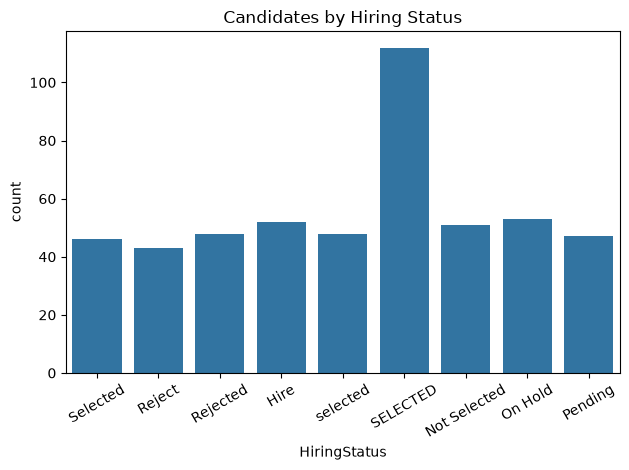

In [71]:
sns.countplot(data=df, x='HiringStatus')
plt.title('Candidates by Hiring Status')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation:
The SELECTED category has the highest number of candidates, while Reject has the lowest number of candidates.

#### 2. Experience Distribution

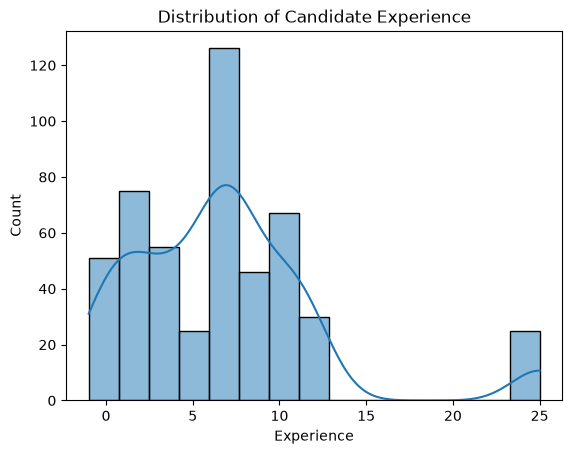

In [72]:
sns.histplot(data=df, x='Experience', bins=15, kde=True)
plt.title('Distribution of Candidate Experience')
plt.show()

### observation:
Most candidates have around 6–8 years of experience, while very few candidates have more than 13 years of experience.

#### 3. Average Score Distribution

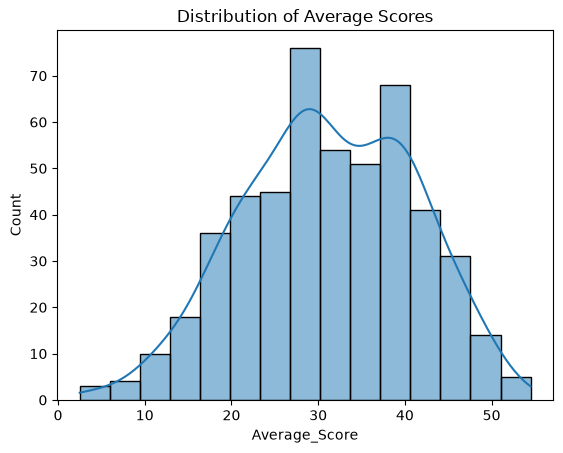

In [73]:
sns.histplot(data=df, x='Average_Score', bins=15, kde=True)
plt.title('Distribution of Average Scores')
plt.show()

### Observation:
Most candidates have average scores between 25 and 40, with the highest concentration around 28–30. Very few candidates have scores below 5 or above 50.

#### 4. Experience by Hiring Status

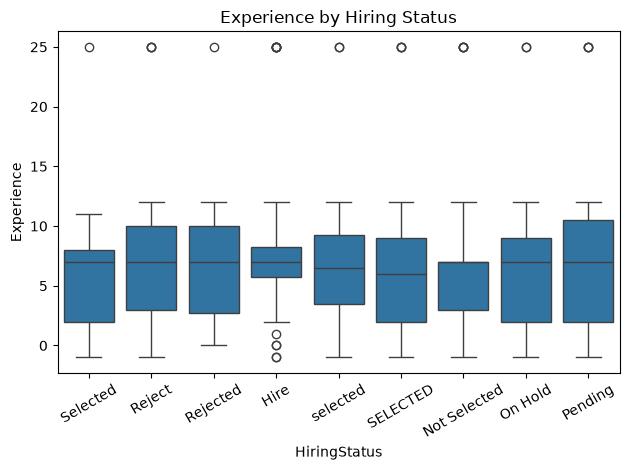

In [74]:
sns.boxplot(data=df, x='HiringStatus', y='Experience')
plt.title('Experience by Hiring Status')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation:
Candidates across all hiring statuses have a similar median experience of around 6–7 years.

#### 5. Average Expected Salary by Applied Role

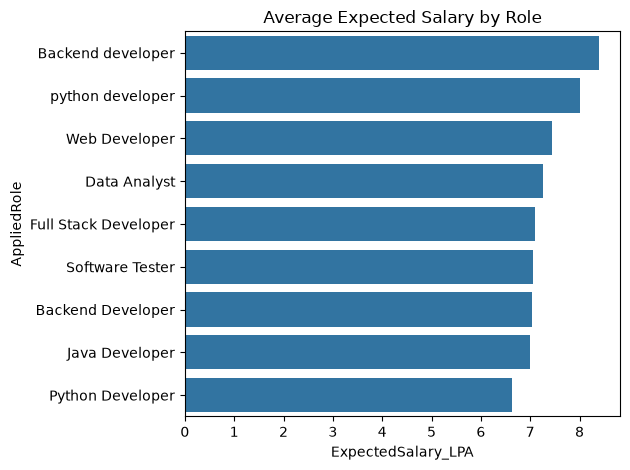

In [75]:
salary_by_role = (
    df.groupby('AppliedRole', as_index=False)['ExpectedSalary_LPA']
      .mean()
      .sort_values('ExpectedSalary_LPA', ascending=False)
)

sns.barplot(
    data=salary_by_role,
    x='ExpectedSalary_LPA',
    y='AppliedRole'
)
plt.title('Average Expected Salary by Role')
plt.tight_layout()
plt.show()

### Observation:
Backend developer has a high Expected salary compare with all role and less expected salary for Python developer.

#### 6. Candidate Skill Distribution

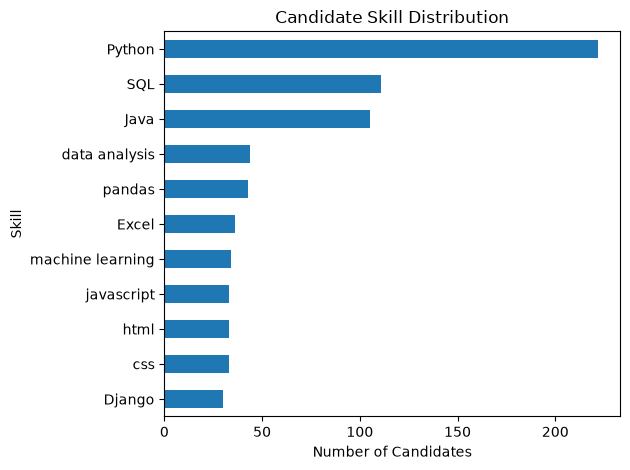

In [76]:
df[skill_cols].sum().sort_values().plot(kind='barh')

plt.title('Candidate Skill Distribution')
plt.xlabel('Number of Candidates')
plt.ylabel('Skill')
plt.tight_layout()
plt.show()

### Observation:
Most candidates have skills in Python, while very few candidates have skills in Django.

###  Conclusion – Job Applicants Analysis

The Job Applicants Analysis project was developed using Python, Pandas, Matplotlib, and Seaborn to analyze job applicant data and identify useful insights about candidates and recruitment trends.

In this project, I performed data cleaning, handled missing values, explored candidate information, and visualized the data using different charts. I analyzed hiring status, candidate experience, average scores, expected salaries across job roles, and candidate skills.

The analysis revealed that the dataset contains more candidates under the selected status than the rejected status. Most candidates have around 6–8 years of experience, and most average scores fall between 25 and 40. Python is a common skill among candidates, while Django appears less common. The Backend Developer role has the highest average expected salary among the roles shown in the analysis.

Through this project, I learned how to clean and analyze real-world datasets, handle missing and inconsistent data, use Pandas for data manipulation, and create visualizations to understand patterns and trends.

